# Rôle 1 : modèles de rentabilité et de risque

1. Préparation : jeux, rentabilités aberrantes, mesures
2. Modèles de référence (tâche 5) : `DummyRegressor`, `LinearRegression`, `DummyClassifier`

Règles suivies dans tout le notebook :

- les modèles sont appris sur le **jeu d'entraînement** (1 050 projets) et comparés sur le **jeu de validation** (225 projets) ;
- le prétraitement (`supervise.creer_pretraitement`) est placé dans un `Pipeline` avec le modèle : il n'apprend que sur l'entraînement ;
- toute règle de nettoyage est **apprise sur l'entraînement seulement**, puis appliquée telle quelle à la validation ;
- le **jeu de test n'est pas utilisé ici** : il sera ouvert une seule fois, à la fin, pour le modèle choisi (tâche 8).

Rappel : `rentabilite` et `risque` sont **simulées** (voir `data/README.md`) ; le bruit de la simulation empêche tout modèle d'être parfait. Le contrôle du script de préparation donne un R² d'environ 0,55 et 58 % de bonnes classes de risque avec un modèle linéaire.

In [1]:
import logging
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.pipeline import Pipeline

RACINE = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(RACINE))
from src import supervise

logging.basicConfig(level=logging.INFO, format="%(message)s")
GRAINE = 42
# LightGBM signale à tort des noms de colonnes différents entre fit et predict dans un Pipeline.
warnings.filterwarnings("ignore", message="X does not have valid feature names")
pd.set_option("display.width", 120)

## 1. Préparation

In [2]:
jeux = supervise.charger_jeux()
entrainement, validation = jeux["entrainement"], jeux["validation"]

Jeux chargés : {'entrainement': 1050, 'validation': 225, 'test': 225}


### 1.1 Rentabilités aberrantes : une règle apprise sur l'entraînement

L'analyse exploratoire a montré quelques rentabilités très loin des autres (au-delà de ±35 %, alors que la moitié des projets est entre 6 et 11 %). Une régression par moindres carrés élève les erreurs au carré : quelques points de ce genre peuvent tirer tout le modèle.

On ne peut pas savoir d'avance quels projets sont faux. On utilise donc une **règle statistique classique**, apprise sur l'entraînement seulement :

- Q1 et Q3 sont les quartiles de la rentabilité (25 % et 75 % des projets en dessous) ; IQR = Q3 − Q1 est l'écart interquartile ;
- une rentabilité est **aberrante** si elle sort de **[Q1 − 3·IQR ; Q3 + 3·IQR]**.

Le facteur 3 (au lieu du 1,5 des boîtes à moustaches) ne vise que les valeurs **très** éloignées. Les quartiles ne bougent presque pas à cause de quelques valeurs extrêmes : la règle n'est pas faussée par ce qu'elle doit repérer.

In [3]:
bornes = supervise.bornes_rentabilite(entrainement[supervise.CIBLE_REGRESSION])
print(f"Bornes apprises sur l'entraînement : [{bornes[0]:.1f} % ; {bornes[1]:.1f} %]")

hors_bornes = pd.DataFrame({
    nom: [len(jeu), (~supervise.dans_les_bornes(jeu, bornes)).sum()]
    for nom, jeu in jeux.items()
}, index=["projets", "rentabilité hors bornes"])
hors_bornes

Bornes apprises sur l'entraînement : [-6.1 % ; 23.3 %]


,entrainement,validation,test
projets,1050,225,225
rentabilité hors bornes,6,2,2


Les **mêmes bornes** (apprises sur l'entraînement) sont appliquées à la validation et au test : on ne recalcule rien sur ces jeux.

**Vérification après coup.** Le fichier `anomalies_injectees.csv` donne la liste des anomalies fabriquées. Il ne sert **ni à apprendre ni à filtrer** : seulement à contrôler, une fois la règle appliquée, ce qu'elle a attrapé.

In [4]:
anomalies = pd.read_csv(RACINE / "data" / "processed" / "anomalies_injectees.csv")
controle = pd.concat([jeu.assign(jeu=nom) for nom, jeu in jeux.items()])
controle["hors bornes"] = ~supervise.dans_les_bornes(controle, bornes)
controle = controle.merge(anomalies[["id_projet", "type_anomalie"]], on="id_projet", how="left")
controle["type_anomalie"] = controle["type_anomalie"].fillna("aucune")
pd.crosstab(controle["type_anomalie"], controle["hors bornes"], margins=True)

hors bornes,False,True,All
type_anomalie,,,
aucune,1475,0,1475
cout_aberrant,7,0,7
duree_incoherente,8,0,8
rentabilite_extreme,0,10,10
All,1490,10,1500


La règle attrape les **10 rentabilités fabriquées** (`rentabilite_extreme`) des projets terminés, et **aucun projet normal** ni aucune autre anomalie. C'est logique : les anomalies de coût ou de durée faussent une **entrée**, pas la rentabilité, donc une règle sur la rentabilité ne peut pas les voir. Ces projets restent dans l'entraînement ; le passage du coût au log10 atténue déjà les coûts multipliés par 10 à 50. Leur repérage est le travail du rôle 2.

Le risque n'est pas touché par ces anomalies : il a été calculé avant leur injection.

### 1.2 Mesures

In [5]:
validation_dans_bornes = validation[supervise.dans_les_bornes(validation, bornes)]
jeux_evaluation = {"validation complète": validation, "validation dans les bornes": validation_dans_bornes}
print({nom: len(jeu) for nom, jeu in jeux_evaluation.items()})


def pipeline(modele) -> Pipeline:
    """Prétraitement commun suivi du modèle : tout s'ajuste sur les données passées à fit."""
    return Pipeline([("pretraitement", supervise.creer_pretraitement()), ("modele", modele)])


def mesures_regression(y_vrai, y_predit) -> dict:
    """RMSE, MAE (en points de rentabilité) et R²."""
    return {"RMSE": root_mean_squared_error(y_vrai, y_predit),
            "MAE": mean_absolute_error(y_vrai, y_predit),
            "R2": r2_score(y_vrai, y_predit)}


def mesures_classification(y_vrai, y_predit) -> dict:
    """Exactitude et F1 macro (moyenne des F1 des trois classes, chacune avec le même poids)."""
    return {"exactitude": accuracy_score(y_vrai, y_predit),
            "F1 macro": f1_score(y_vrai, y_predit, average="macro")}

{'validation complète': 225, 'validation dans les bornes': 223}


Les mesures de régression sont calculées sur deux versions de la validation :

- **validation complète** (225 projets), telle qu'elle arrive ;
- **validation dans les bornes** (223 projets) : sans les rentabilités que la règle apprise sur l'entraînement juge aberrantes.

**Les mesures.**

- **RMSE** (racine de l'erreur quadratique moyenne) : l'erreur typique, en points de rentabilité. Elle élève les erreurs au carré, donc punit fort les grosses erreurs.
- **MAE** (erreur absolue moyenne) : l'erreur moyenne en points, moins sensible aux valeurs extrêmes.
- **R²** : part de la variance de la rentabilité expliquée par le modèle. 0 = pas mieux que prédire la moyenne ; 1 = parfait ; négatif = pire que la moyenne.
- **Exactitude** : part de projets bien classés.
- **F1 macro** : pour chaque classe, le F1 combine précision et rappel ; on fait la moyenne des trois classes sans pondérer par leur taille. Un modèle qui ignore la classe rare `eleve` est donc pénalisé, alors que son exactitude peut rester correcte.

## 2. Modèles de référence (tâche 5)

Un modèle de référence donne le niveau à battre. Sans lui, un R² ou une exactitude ne veulent rien dire.

- `DummyRegressor` : prédit toujours la **moyenne** de la rentabilité d'entraînement ;
- `LinearRegression` : régression linéaire par moindres carrés, sans régularisation ;
- `DummyClassifier` : répond toujours la **classe la plus fréquente** (`most_frequent`), ou tire une classe au hasard selon les proportions d'entraînement (`stratified`).

### 2.1 Régression de la rentabilité

On apprend chaque modèle sur deux versions de l'entraînement, pour mesurer l'effet des rentabilités aberrantes :

- **tout l'entraînement** (1 050 projets) ;
- **entraînement dans les bornes** (sans les rentabilités hors de la règle).

In [6]:
versions_entrainement = {
    "tout l'entraînement": entrainement,
    "entraînement dans les bornes": entrainement[supervise.dans_les_bornes(entrainement, bornes)],
}
modeles_reference = {"DummyRegressor (moyenne)": DummyRegressor(strategy="mean"),
                     "LinearRegression": LinearRegression()}

lignes = []
for nom_entrainement, donnees in versions_entrainement.items():
    for nom_modele, modele in modeles_reference.items():
        ajuste = pipeline(modele).fit(donnees[supervise.VARIABLES], donnees[supervise.CIBLE_REGRESSION])
        ligne = {"modèle": nom_modele, "entraînement": nom_entrainement, "projets appris": len(donnees)}
        ligne["R2 entraînement"] = r2_score(donnees[supervise.CIBLE_REGRESSION],
                                            ajuste.predict(donnees[supervise.VARIABLES]))
        for nom_evaluation, evaluation in jeux_evaluation.items():
            predit = ajuste.predict(evaluation[supervise.VARIABLES])
            for mesure, valeur in mesures_regression(evaluation[supervise.CIBLE_REGRESSION], predit).items():
                ligne[f"{mesure} ({nom_evaluation})"] = valeur
        lignes.append(ligne)

resultats_reference = pd.DataFrame(lignes)
resultats_reference.round(3)

,modèle,entraînement,projets appris,R2 entraînement,RMSE (validation complète),MAE (validation complète),R2 (validation complète),RMSE (validation dans les bornes),MAE (validation dans les bornes),R2 (validation dans les bornes)
0,DummyRegressor (moyenne),tout l'entraînement,1050,0.000,5.496,2.660,-0.021,2.803,2.262,-0.053
1,LinearRegression,tout l'entraînement,1050,0.405,5.286,2.210,0.056,2.413,1.816,0.219
2,DummyRegressor (moyenne),entraînement dans les bornes,1044,0.000,5.478,2.639,-0.014,2.775,2.240,-0.033
3,LinearRegression,entraînement dans les bornes,1044,0.665,5.230,2.035,0.076,2.142,1.632,0.385


In [7]:
colonnes = ["modèle", "entraînement", "R2 entraînement",
            "RMSE (validation complète)", "R2 (validation complète)",
            "RMSE (validation dans les bornes)", "MAE (validation dans les bornes)",
            "R2 (validation dans les bornes)"]
resultats_reference[colonnes].round(3)

,modèle,entraînement,R2 entraînement,RMSE (validation complète),R2 (validation complète),RMSE (validation dans les bornes),MAE (validation dans les bornes),R2 (validation dans les bornes)
0,DummyRegressor (moyenne),tout l'entraînement,0.000,5.496,-0.021,2.803,2.262,-0.053
1,LinearRegression,tout l'entraînement,0.405,5.286,0.056,2.413,1.816,0.219
2,DummyRegressor (moyenne),entraînement dans les bornes,0.000,5.478,-0.014,2.775,2.240,-0.033
3,LinearRegression,entraînement dans les bornes,0.665,5.230,0.076,2.142,1.632,0.385


Ce que montre le tableau :

1. **Le modèle « moyenne » a un R² proche de 0**, par construction : c'est le plancher. Son erreur typique est d'environ 2,8 points sur la validation dans les bornes.
2. **Les rentabilités aberrantes de l'entraînement faussent l'apprentissage** : les retirer fait passer le R² de la régression linéaire d'environ 0,22 à 0,39 sur la validation dans les bornes, et sa MAE de 1,8 à 1,6 point.
3. **Les 2 rentabilités aberrantes de la validation écrasent les mesures** : avec elles, la RMSE fait plus que doubler (de 2,1 à 5,2 points) et le R² tombe sous 0,1, quel que soit le modèle. Ces deux projets représentent 1 % de la validation mais l'essentiel de l'erreur au carré. On donne les deux mesures : la validation complète dit ce qui se passe sur des données telles qu'elles arrivent, la validation dans les bornes dit ce que le modèle sait vraiment prédire.
4. **La régression linéaire apprend trop les données d'entraînement** : R² de 0,67 sur l'entraînement contre 0,39 en validation. Avec 175 colonnes pour un millier de projets, dont 158 pays souvent représentés par un ou deux projets, elle donne à chaque pays rare un coefficient qui colle au bruit de ces quelques projets. C'est exactement ce que la régularisation (Ridge, Lasso, ElasticNet, tâche 6) doit corriger, et ce qui explique qu'on reste sous le plafond d'environ 0,55 annoncé par le script de préparation.

### 2.2 Classification du risque

In [8]:
lignes = []
for strategie in ["most_frequent", "stratified"]:
    ajuste = pipeline(DummyClassifier(strategy=strategie, random_state=GRAINE)).fit(
        entrainement[supervise.VARIABLES], entrainement[supervise.CIBLE_CLASSIFICATION])
    predit = ajuste.predict(validation[supervise.VARIABLES])
    lignes.append({"modèle": f"DummyClassifier ({strategie})",
                   **mesures_classification(validation[supervise.CIBLE_CLASSIFICATION], predit)})
resultats_reference_risque = pd.DataFrame(lignes)
resultats_reference_risque.round(3)

,modèle,exactitude,F1 macro
0,DummyClassifier (most_frequent),0.400,0.190
1,DummyClassifier (stratified),0.356,0.333


- **Toujours la classe la plus fréquente** : 40 % d'exactitude (la classe `faible`, à égalité avec `moyen`, représente 40 % des projets), mais un F1 macro de 0,19, car deux classes sur trois ne sont jamais prédites.
- **Tirage au hasard selon les proportions** : exactitude d'environ 36 % et F1 macro d'environ 0,33 ; il prédit toutes les classes, mais au hasard.

Ce sont les niveaux à battre : un classifieur utile doit dépasser **40 % d'exactitude** et un **F1 macro de 0,33**. Le contrôle du script de préparation annonce environ 58 % pour un modèle linéaire.

Pour le risque, on garde tous les projets, en entraînement comme en validation.

### 2.3 Bilan des modèles de référence

| Tâche | Référence | Validation complète | Validation dans les bornes |
|---|---|---|---|
| Rentabilité | moyenne d'entraînement | R² ≈ 0, RMSE ≈ 5,5 points | R² ≈ 0, RMSE ≈ 2,8 points |
| Rentabilité | régression linéaire, entraînement dans les bornes | R² ≈ 0,08, RMSE ≈ 5,2 points | R² ≈ 0,39, RMSE ≈ 2,1 points |
| Risque | classe la plus fréquente | exactitude 40 %, F1 macro 0,19 | (identique) |
| Risque | tirage selon les proportions | exactitude ≈ 36 %, F1 macro ≈ 0,33 | (identique) |

Choix pour la suite :

- les modèles de rentabilité sont appris sur l'**entraînement dans les bornes** (règle Q1 − 3·IQR ; Q3 + 3·IQR apprise sur l'entraînement) ;
- ils sont mesurés sur la **validation complète** et sur la **validation dans les bornes** (mêmes bornes) ; le test sera traité de la même façon.

## 3. Régression régularisée (tâche 6)

La régression linéaire choisit les coefficients qui minimisent l'erreur au carré sur l'entraînement, sans aucune retenue : avec 175 colonnes, elle donne à chaque pays rare un coefficient qui colle à ses un ou deux projets. La **régularisation** ajoute une pénalité sur la taille des coefficients :

- **Ridge** (pénalité L2) : minimise erreur² + α × somme des coefficients². Tous les coefficients sont rapetissés vers 0, sans devenir exactement nuls.
- **Lasso** (pénalité L1) : minimise erreur² + α × somme des |coefficients|. Une partie des coefficients devient **exactement 0** : Lasso fait aussi une sélection de variables.
- **ElasticNet** : mélange des deux ; `l1_ratio` donne la part de L1 (1 = Lasso, 0 = Ridge).

α règle la force de la pénalité : α = 0 redonne la régression linéaire ; α très grand écrase tous les coefficients et revient à prédire la moyenne. La standardisation du prétraitement est indispensable ici : sans elle, la pénalité frapperait plus fort les variables à petite échelle.

**Choix de α par validation croisée à 5 plis** (`GridSearchCV`) : l'entraînement (dans les bornes) est coupé en 5 parts ; pour chaque valeur de la grille, on apprend sur 4 parts et on mesure la RMSE sur la cinquième, 5 fois, puis on fait la moyenne. Le jeu de validation n'intervient pas dans ce choix : il sert ensuite à comparer les modèles déjà réglés. Le prétraitement étant dans le `Pipeline`, il est réajusté sur les 4 parts d'apprentissage à chaque pli.

Petite réserve : les bornes de la règle IQR sont calculées une fois sur tout l'entraînement, avant la validation croisée. C'est un nettoyage de la cible, pas une transformation des entrées, et les quartiles changent à peine d'un pli à l'autre : l'effet est négligeable.

In [9]:
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.model_selection import GridSearchCV, KFold
import matplotlib.pyplot as plt

FIGURES = RACINE / "reports" / "role1" / "figures"
plis = KFold(n_splits=5, shuffle=True, random_state=GRAINE)
entrainement_bornes = versions_entrainement["entraînement dans les bornes"]

grilles = {
    "Ridge": (Ridge(), {"modele__alpha": np.logspace(-2, 3, 11)}),
    "Lasso": (Lasso(max_iter=50_000), {"modele__alpha": np.logspace(-4, 0, 9)}),
    "ElasticNet": (ElasticNet(max_iter=50_000), {"modele__alpha": np.logspace(-4, 0, 9),
                                                  "modele__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]}),
}

recherches = {}
for nom, (modele, grille) in grilles.items():
    recherches[nom] = GridSearchCV(pipeline(modele), grille, cv=plis,
                                   scoring="neg_root_mean_squared_error").fit(
        entrainement_bornes[supervise.VARIABLES], entrainement_bornes[supervise.CIBLE_REGRESSION])
    print(f"{nom:<11} meilleurs réglages : {recherches[nom].best_params_} ; "
          f"RMSE en validation croisée : {-recherches[nom].best_score_:.3f}")

Ridge       meilleurs réglages : {'modele__alpha': np.float64(3.1622776601683795)} ; RMSE en validation croisée : 2.120


Lasso       meilleurs réglages : {'modele__alpha': np.float64(0.0031622776601683794)} ; RMSE en validation croisée : 2.136


ElasticNet  meilleurs réglages : {'modele__alpha': np.float64(0.0031622776601683794), 'modele__l1_ratio': 0.1} ; RMSE en validation croisée : 2.118


Aucun α retenu n'est au bord de sa grille : la grille est assez large. ElasticNet choisit `l1_ratio = 0,1`, donc surtout de la pénalité L2 : il se rapproche de Ridge.

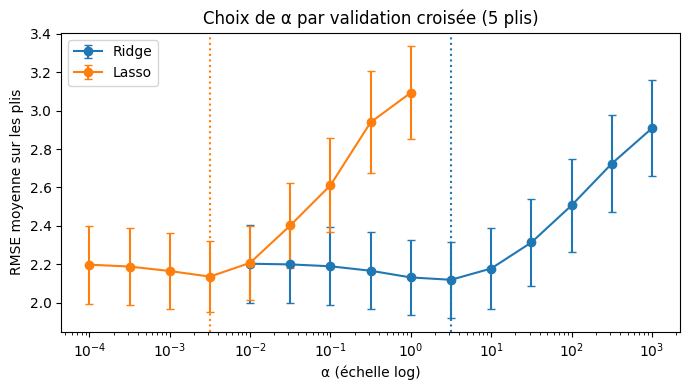

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
for nom in ["Ridge", "Lasso"]:
    cv = pd.DataFrame(recherches[nom].cv_results_)
    ax.errorbar(cv["param_modele__alpha"].astype(float), -cv["mean_test_score"], yerr=cv["std_test_score"],
                marker="o", capsize=3, label=nom)
    ax.axvline(recherches[nom].best_params_["modele__alpha"], linestyle=":",
               color=ax.lines[-1].get_color())
ax.set_xscale("log")
ax.set(title="Choix de α par validation croisée (5 plis)", xlabel="α (échelle log)",
       ylabel="RMSE moyenne sur les plis")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "regularisation_alpha.png", dpi=120)
plt.show()

Les deux courbes ont la forme attendue en U : à gauche (α petit), le modèle colle au bruit et l'erreur remonte un peu ; à droite (α grand), il est trop contraint et l'erreur monte fortement jusqu'au niveau du modèle « moyenne ». Le minimum (pointillés) est entre les deux. Les barres d'écart-type entre plis sont larges devant les écarts entre α voisins : le réglage exact compte peu tant qu'on reste près du creux.

In [11]:
lignes = []
modeles_a_comparer = {"LinearRegression": pipeline(LinearRegression()).fit(
    entrainement_bornes[supervise.VARIABLES], entrainement_bornes[supervise.CIBLE_REGRESSION])}
modeles_a_comparer.update({nom: r.best_estimator_ for nom, r in recherches.items()})

for nom, modele in modeles_a_comparer.items():
    ligne = {"modèle": nom,
             "réglages": recherches[nom].best_params_ if nom in recherches else "",
             "RMSE validation croisée": -recherches[nom].best_score_ if nom in recherches else np.nan,
             "R2 entraînement": r2_score(entrainement_bornes[supervise.CIBLE_REGRESSION],
                                         modele.predict(entrainement_bornes[supervise.VARIABLES]))}
    for nom_evaluation, evaluation in jeux_evaluation.items():
        predit = modele.predict(evaluation[supervise.VARIABLES])
        for mesure, valeur in mesures_regression(evaluation[supervise.CIBLE_REGRESSION], predit).items():
            ligne[f"{mesure} ({nom_evaluation})"] = valeur
    lignes.append(ligne)

resultats_regularisation = pd.DataFrame(lignes)
resultats_regularisation.drop(columns="réglages").round(3)

,modèle,RMSE validation croisée,R2 entraînement,RMSE (validation complète),MAE (validation complète),R2 (validation complète),RMSE (validation dans les bornes),MAE (validation dans les bornes),R2 (validation dans les bornes)
0,LinearRegression,NaN,0.665,5.230,2.035,0.076,2.142,1.632,0.385
1,Ridge,2.120,0.638,5.192,2.006,0.089,2.050,1.604,0.436
2,Lasso,2.136,0.637,5.200,2.037,0.086,2.074,1.634,0.423
3,ElasticNet,2.118,0.637,5.192,2.008,0.089,2.051,1.606,0.436


Ce que montre le tableau :

1. **Les trois modèles régularisés battent la régression linéaire** sur la validation dans les bornes : R² d'environ 0,42 à 0,44 contre 0,39, erreur typique de 2,05 à 2,07 points contre 2,14.
2. **L'écart entre entraînement et validation se réduit** : la régularisation empêche le modèle d'apprendre par cœur les pays rares.
3. **Ridge et ElasticNet sont pratiquement à égalité**, Lasso un peu derrière. Les écarts entre eux (quelques millièmes de RMSE) sont bien plus petits que l'écart-type entre plis de la validation croisée : on ne peut pas dire que l'un est vraiment meilleur que l'autre.
4. **Sur la validation complète, tous les modèles restent sous un R² de 0,1** : les deux rentabilités aberrantes dominent l'erreur, et aucun modèle ne peut les prédire.
5. **On reste sous le plafond d'environ 0,55** du contrôle de préparation. Une explication probable : la formule de simulation contient une courbure en durée (`z_duree²`) et une interaction coût × secteur (énergie et transport), que ces modèles linéaires ne voient pas. Les modèles à arbres de la tâche 7 peuvent les capter ; l'écart restant peut aussi venir du jeu plus petit (1 044 projets contre 1 200 dans le contrôle).

### 3.1 Variables mises à zéro par Lasso

In [12]:
lasso = recherches["Lasso"].best_estimator_
coefficients = pd.Series(lasso["modele"].coef_,
                         index=lasso["pretraitement"].get_feature_names_out(), name="coefficient")


def variable_d_origine(colonne: str) -> str:
    """Nom de la variable d'origine d'une colonne encodée (secteur_Énergie -> secteur)."""
    for variable in supervise.VARIABLES_CATEGORIELLES:
        if colonne.startswith(variable + "_"):
            return variable
    return colonne


resume = coefficients.to_frame().assign(variable=lambda d: d.index.map(variable_d_origine),
                                        nul=lambda d: d["coefficient"] == 0)
resume_par_variable = resume.groupby("variable", sort=False)["nul"].agg(colonnes="size", mises_a_zero="sum")
print(f"Lasso (α = {recherches['Lasso'].best_params_['modele__alpha']:.4f}) met à zéro "
      f"{int(resume['nul'].sum())} colonnes sur {len(resume)}.")
resume_par_variable

Lasso (α = 0.0032) met à zéro 66 colonnes sur 175.


,colonnes,mises_a_zero
variable,,
cout_total,1,0
duree_mois,1,0
annee_approbation,1,0
secteur,11,1
pays,149,63
region,8,2
type_financement,4,0


In [13]:
print("Colonnes mises à zéro, hors pays :")
print(resume[resume["nul"] & (resume["variable"] != "pays")].index.tolist())
print()
print("Plus gros coefficients (en valeur absolue), hors pays :")
hors_pays = resume[resume["variable"] != "pays"]
hors_pays.reindex(hors_pays["coefficient"].abs().sort_values(ascending=False).index).head(12)["coefficient"].round(2)

Colonnes mises à zéro, hors pays :
['secteur_Agriculture', 'region_Asie du Sud', 'region_Europe et Asie centrale']

Plus gros coefficients (en valeur absolue), hors pays :


secteur_Énergie                  2.93
secteur_Protection sociale      -2.01
secteur_Gouvernance             -1.95
secteur_Transport                1.58
duree_mois                      -1.38
secteur_Numérique                1.35
secteur_Santé                   -1.19
secteur_Industrie et commerce    1.18
type_financement_IBRD            1.06
secteur_Éducation               -0.90
type_financement_Dons           -0.88
cout_total                      -0.71
Name: coefficient, dtype: float64

Lecture :

- **Les pays sont la variable la plus élaguée** : 63 colonnes sur 149 (environ 4 sur 10) sont mises à zéro. Lasso garde les pays dont l'effet est net et range les autres au niveau de leur région.
- **La région ne perd que 2 colonnes sur 8**, alors que la formule de simulation n'en a pas besoin (la rentabilité dépend du pays, pas de la région). Explication : pour Lasso, un seul coefficient de région qui résume plusieurs pays voisins coûte moins cher en pénalité que plusieurs coefficients de pays. La région sert alors de raccourci, pas de cause.
- **`secteur_Agriculture` est mis à zéro** : dans la formule, l'agriculture a un effet de 0, c'est le secteur de référence. Lasso le retrouve sans qu'on le lui dise.
- **Les coefficients retrouvent la formule de simulation** (sans qu'on la lui donne) :

| Variable | Coefficient Lasso | Effet dans la formule |
|---|---|---|
| secteur Énergie | +2,9 | +2,5 |
| secteur Protection sociale | −2,0 | −2,0 |
| secteur Gouvernance | −2,0 | −2,0 |
| secteur Transport | +1,6 | +1,5 |
| secteur Numérique | +1,4 | +2,0 |
| secteur Santé | −1,2 | −1,5 |
| durée (par écart-type) | −1,4 | −1,2 (plus la courbure) |
| financement IBRD | +1,1 | +1 |
| financement Dons | −0,9 | −1 |
| log10 du coût (par écart-type) | −0,7 | −0,8 (+1 pour énergie et transport) |

Les coefficients sont un peu rapetissés ou déformés par la pénalité et par ce que le modèle linéaire ne voit pas (courbure de la durée, interaction coût × secteur), mais les signes et les ordres de grandeur sont les bons. Le numérique, avec peu de projets, est le plus mal estimé.

Comme les variables sont standardisées, la taille d'un coefficient de durée ou de coût se lit en points de rentabilité par écart-type ; pour une indicatrice de catégorie, c'est l'écart en points par rapport aux projets qui n'ont pas cette catégorie, à autres variables égales.

### 3.2 Et les modèles à arbres ?

La formule de simulation contient une courbure en durée et une interaction coût × secteur, que les modèles linéaires ne voient pas. Les modèles à arbres découpent les données par seuils successifs et peuvent capter ce genre d'effet sans qu'on le leur indique. On essaie donc les deux modèles à arbres de la tâche 7 sur la rentabilité, réglés de la même façon (validation croisée à 5 plis sur l'entraînement dans les bornes) :

- **forêt aléatoire** (`RandomForestRegressor`) : 300 arbres appris chacun sur un tirage des projets et des colonnes, dont on fait la moyenne ;
- **LightGBM** (`LGBMRegressor`) : boosting de gradient, des petits arbres ajoutés un par un, chacun corrigeant les erreurs des précédents.

In [14]:
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor

grilles_arbres = {
    "Forêt aléatoire": (RandomForestRegressor(n_estimators=300, random_state=GRAINE, n_jobs=-1),
                        {"modele__max_depth": [None, 8, 16], "modele__min_samples_leaf": [1, 3, 10],
                         "modele__max_features": [0.3, 1.0]}),
    "LightGBM": (LGBMRegressor(random_state=GRAINE, verbose=-1, n_jobs=1),
                 {"modele__n_estimators": [200, 500], "modele__learning_rate": [0.03, 0.1],
                  "modele__num_leaves": [7, 15], "modele__min_child_samples": [10, 30]}),
}
for nom, (modele, grille) in grilles_arbres.items():
    recherches[nom] = GridSearchCV(pipeline(modele), grille, cv=plis,
                                   scoring="neg_root_mean_squared_error").fit(
        entrainement_bornes[supervise.VARIABLES], entrainement_bornes[supervise.CIBLE_REGRESSION])
    print(f"{nom:<16} meilleurs réglages : {recherches[nom].best_params_} ; "
          f"RMSE en validation croisée : {-recherches[nom].best_score_:.3f}")

lignes = []
for nom in grilles_arbres:
    modele = recherches[nom].best_estimator_
    ligne = {"modèle": nom, "réglages": recherches[nom].best_params_,
             "RMSE validation croisée": -recherches[nom].best_score_,
             "R2 entraînement": r2_score(entrainement_bornes[supervise.CIBLE_REGRESSION],
                                         modele.predict(entrainement_bornes[supervise.VARIABLES]))}
    for nom_evaluation, evaluation in jeux_evaluation.items():
        predit = modele.predict(evaluation[supervise.VARIABLES])
        for mesure, valeur in mesures_regression(evaluation[supervise.CIBLE_REGRESSION], predit).items():
            ligne[f"{mesure} ({nom_evaluation})"] = valeur
    lignes.append(ligne)

resultats_rentabilite = pd.concat([resultats_regularisation, pd.DataFrame(lignes)], ignore_index=True)
resultats_rentabilite.drop(columns="réglages").round(3)

Forêt aléatoire  meilleurs réglages : {'modele__max_depth': None, 'modele__max_features': 0.3, 'modele__min_samples_leaf': 1} ; RMSE en validation croisée : 2.250


LightGBM         meilleurs réglages : {'modele__learning_rate': 0.03, 'modele__min_child_samples': 10, 'modele__n_estimators': 500, 'modele__num_leaves': 7} ; RMSE en validation croisée : 2.210


,modèle,RMSE validation croisée,R2 entraînement,RMSE (validation complète),MAE (validation complète),R2 (validation complète),RMSE (validation dans les bornes),MAE (validation dans les bornes),R2 (validation dans les bornes)
0,LinearRegression,NaN,0.665,5.230,2.035,0.076,2.142,1.632,0.385
1,Ridge,2.120,0.638,5.192,2.006,0.089,2.050,1.604,0.436
2,Lasso,2.136,0.637,5.200,2.037,0.086,2.074,1.634,0.423
3,ElasticNet,2.118,0.637,5.192,2.008,0.089,2.051,1.606,0.436
4,Forêt aléatoire,2.250,0.931,5.280,2.126,0.058,2.116,1.715,0.399
5,LightGBM,2.210,0.703,5.319,2.162,0.044,2.163,1.749,0.372


**Les arbres font moins bien que Ridge** sur la rentabilité, en validation croisée comme en validation : c'est le résultat inverse de ce qu'on pouvait espérer. Explication probable : l'essentiel de la rentabilité simulée est une **somme d'effets** (secteur + pays + financement + durée), exactement la forme d'un modèle linéaire. L'effet pays, en particulier, porte sur 158 catégories souvent représentées par un ou deux projets : un modèle linéaire régularisé l'estime par un coefficient par pays, rapetissé vers 0, alors qu'un arbre doit isoler chaque pays par des découpages successifs et n'y arrive pas avec si peu de projets. Le gain sur la courbure de la durée ne compense pas cette perte.

La forêt a un R² d'entraînement de 0,93 : elle apprend beaucoup par cœur, même réglée par validation croisée.

Un modèle plus avancé n'est donc pas toujours meilleur : ici, le modèle simple et régularisé est le bon choix pour la rentabilité.

### 3.3 Bilan de la régression

| Modèle | Réglage (validation croisée) | R² validation dans les bornes | R² validation complète |
|---|---|---|---|
| LinearRegression | — | 0,39 | 0,08 |
| Ridge | α ≈ 3,2 | 0,44 | 0,09 |
| Lasso | α ≈ 0,003 | 0,42 | 0,09 |
| ElasticNet | α ≈ 0,003, l1_ratio 0,1 | 0,44 | 0,09 |
| Forêt aléatoire | profondeur libre, 30 % des colonnes par découpage | 0,40 | 0,06 |
| LightGBM | 500 arbres de 7 feuilles, pas 0,03 | 0,37 | 0,04 |

La régularisation gagne environ 5 points de R² sur la régression linéaire en limitant le surapprentissage ; les arbres ne font pas mieux. Le choix final du modèle de rentabilité se fera à la tâche 8.

## 4. Classification du risque (tâche 7)

Trois modèles, du plus simple au plus avancé :

- **Régression logistique** (multinomiale) : un score linéaire par classe, transformé en probabilités qui somment à 1 (fonction softmax). Elle est régularisée comme Ridge : `C` est l'inverse de la force de la pénalité (petit `C` = forte pénalité).
- **Forêt aléatoire** : des centaines d'arbres de décision, chacun appris sur un tirage des projets et ne regardant qu'une partie des colonnes à chaque découpage ; la classe prédite est le vote des arbres. Réglages : profondeur maximale, nombre minimal de projets par feuille, part des colonnes.
- **LightGBM** : boosting de gradient. Des petits arbres sont ajoutés un par un, chacun corrigeant les erreurs des précédents. Réglages : nombre d'arbres, pas d'apprentissage, nombre de feuilles, nombre minimal de projets par feuille.

**Déséquilibre des classes.** La classe `eleve` ne représente que 20 % des projets. Avec `class_weight="balanced"`, chaque erreur sur un projet d'une classe rare compte plus, en proportion inverse de sa fréquence. On laisse la validation croisée décider si c'est utile.

**Réglage.** Validation croisée **stratifiée** à 5 plis sur l'entraînement (chaque pli garde les proportions 40 / 40 / 20), critère : **F1 macro**, pour ne pas favoriser un modèle qui néglige la classe `eleve`. Tous les projets d'entraînement sont gardés : les anomalies ne touchent pas l'étiquette de risque.

On regarde aussi l'**AUC « élevé contre le reste »** : `predict` doit rendre `proba_risque`, la probabilité que le projet soit à risque élevé, et l'AUC mesure si cette probabilité classe bien les projets (1 = parfait, 0,5 = hasard).

In [15]:
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold

plis_stratifies = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)
ORDRE_RISQUE = ["faible", "moyen", "eleve"]
X_entrainement = entrainement[supervise.VARIABLES]
y_entrainement = entrainement[supervise.CIBLE_CLASSIFICATION]

grilles_risque = {
    "Régression logistique": (LogisticRegression(max_iter=5_000),
                              {"modele__C": np.logspace(-3, 2, 11),
                               "modele__class_weight": [None, "balanced"]}),
    "Forêt aléatoire": (RandomForestClassifier(n_estimators=300, random_state=GRAINE, n_jobs=-1),
                        {"modele__max_depth": [None, 8, 16], "modele__min_samples_leaf": [1, 3, 10],
                         "modele__max_features": ["sqrt", 0.3], "modele__class_weight": [None, "balanced"]}),
    "LightGBM": (LGBMClassifier(random_state=GRAINE, verbose=-1, n_jobs=1),
                 {"modele__n_estimators": [100, 300], "modele__learning_rate": [0.03, 0.1],
                  "modele__num_leaves": [7, 15], "modele__min_child_samples": [10, 30],
                  "modele__class_weight": [None, "balanced"]}),
}

recherches_risque = {}
for nom, (modele, grille) in grilles_risque.items():
    recherches_risque[nom] = GridSearchCV(pipeline(modele), grille, cv=plis_stratifies,
                                          scoring="f1_macro").fit(X_entrainement, y_entrainement)
    r = recherches_risque[nom]
    ecart = r.cv_results_["std_test_score"][r.best_index_]
    print(f"{nom:<22} F1 macro en validation croisée : {r.best_score_:.3f} (± {ecart:.3f} entre plis)")
    print(f"{'':<22} réglages : {r.best_params_}")

Régression logistique  F1 macro en validation croisée : 0.650 (± 0.021 entre plis)
                       réglages : {'modele__C': np.float64(0.1), 'modele__class_weight': None}


Forêt aléatoire        F1 macro en validation croisée : 0.618 (± 0.039 entre plis)
                       réglages : {'modele__class_weight': 'balanced', 'modele__max_depth': 8, 'modele__max_features': 0.3, 'modele__min_samples_leaf': 3}


LightGBM               F1 macro en validation croisée : 0.616 (± 0.022 entre plis)
                       réglages : {'modele__class_weight': 'balanced', 'modele__learning_rate': 0.03, 'modele__min_child_samples': 30, 'modele__n_estimators': 300, 'modele__num_leaves': 7}


In [16]:
y_validation = validation[supervise.CIBLE_CLASSIFICATION]
lignes = []
for nom, r in recherches_risque.items():
    modele = r.best_estimator_
    predit = modele.predict(validation[supervise.VARIABLES])
    proba_eleve = modele.predict_proba(validation[supervise.VARIABLES])[:, list(modele.classes_).index("eleve")]
    rappels = recall_score(y_validation, predit, labels=ORDRE_RISQUE, average=None)
    lignes.append({
        "modèle": nom,
        "F1 macro validation croisée": r.best_score_,
        "écart-type entre plis": r.cv_results_["std_test_score"][r.best_index_],
        "exactitude entraînement": accuracy_score(y_entrainement, modele.predict(X_entrainement)),
        **mesures_classification(y_validation, predit),
        "AUC élevé contre le reste": roc_auc_score(y_validation == "eleve", proba_eleve),
        **{f"rappel {classe}": rappel for classe, rappel in zip(ORDRE_RISQUE, rappels)},
    })

resultats_risque = pd.concat([resultats_reference_risque, pd.DataFrame(lignes)], ignore_index=True)
resultats_risque.round(3)

,modèle,exactitude,F1 macro,F1 macro validation croisée,écart-type entre plis,exactitude entraînement,AUC élevé contre le reste,rappel faible,rappel moyen,rappel eleve
0,DummyClassifier (most_frequent),0.400,0.190,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,DummyClassifier (stratified),0.356,0.333,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Régression logistique,0.547,0.531,0.650,0.021,0.695,0.864,0.633,0.544,0.378
3,Forêt aléatoire,0.578,0.572,0.618,0.039,0.764,0.859,0.644,0.533,0.533
4,LightGBM,0.591,0.586,0.616,0.022,0.772,0.863,0.689,0.500,0.578


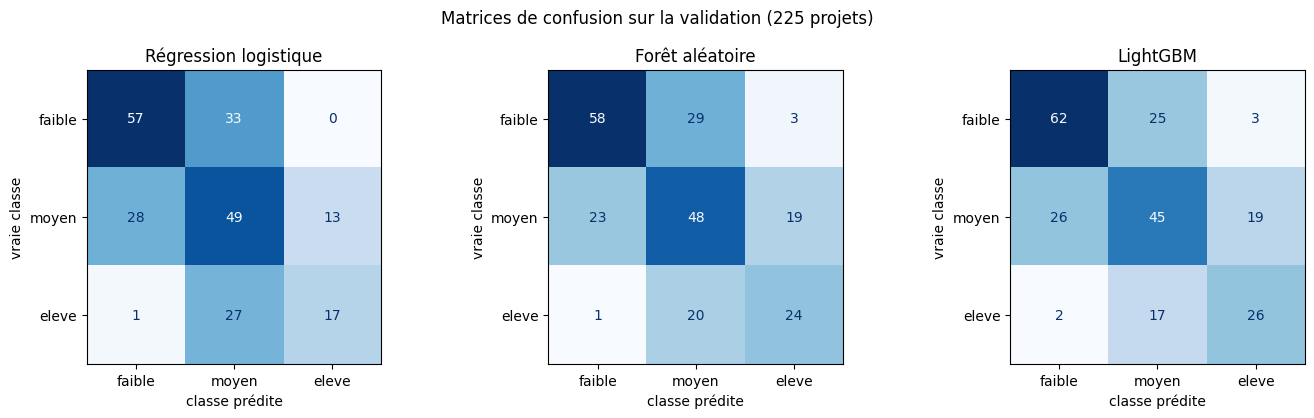

Régression logistique  confusions faible <-> élevé : 1 projets sur 225
Forêt aléatoire        confusions faible <-> élevé : 4 projets sur 225
LightGBM               confusions faible <-> élevé : 5 projets sur 225


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (nom, r) in zip(axes, recherches_risque.items()):
    predit = r.best_estimator_.predict(validation[supervise.VARIABLES])
    ConfusionMatrixDisplay(confusion_matrix(y_validation, predit, labels=ORDRE_RISQUE),
                           display_labels=ORDRE_RISQUE).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set(title=nom, xlabel="classe prédite", ylabel="vraie classe")
    ax.grid(False)
plt.suptitle("Matrices de confusion sur la validation (225 projets)")
plt.tight_layout()
plt.savefig(FIGURES / "confusion_risque.png", dpi=120)
plt.show()

for nom, r in recherches_risque.items():
    matrice = confusion_matrix(y_validation, r.best_estimator_.predict(validation[supervise.VARIABLES]),
                               labels=ORDRE_RISQUE)
    print(f"{nom:<22} confusions faible <-> élevé : {matrice[0, 2] + matrice[2, 0]} projets sur 225")

Ce que montrent le tableau et les matrices de confusion :

1. **Les trois modèles battent nettement les références** : environ 55 à 59 % d'exactitude contre 40 %, et un F1 macro de 0,53 à 0,59 contre 0,19 (classe majoritaire) ou 0,33 (tirage au hasard). On est au niveau du contrôle de préparation (58 %).
2. **Les erreurs se font presque toujours entre classes voisines** (faible ↔ moyen, moyen ↔ élevé) ; confondre un projet faible avec un projet élevé est rare (1 à 5 projets sur 225 selon le modèle). C'est attendu : les classes sont des tranches d'un même score continu, et le bruit de la simulation fait passer des projets proches d'un seuil de l'autre côté.
3. **Le repérage de la classe `eleve` fait la différence.** La régression logistique, que la validation croisée a réglée sans pondération des classes, ne retrouve que 38 % des projets à risque élevé de la validation ; la forêt et LightGBM, réglés avec `class_weight="balanced"`, en retrouvent 53 et 58 %. C'est l'essentiel de leur avance en F1 macro. La classe `moyen`, coincée entre les deux autres, plafonne autour de 50 à 54 % pour tous les modèles.
4. **Pour `proba_risque`, les trois modèles se valent** : AUC « élevé contre le reste » d'environ 0,86. La probabilité de risque élevé classe bien les projets, quel que soit le modèle.
5. **La validation croisée et la validation ne donnent pas le même classement.** En validation croisée (sur 1 050 projets), la régression logistique est en tête ; sur la validation (225 projets), LightGBM et la forêt passent devant. Les deux mesures sont bruitées :
   - l'écart-type entre plis est de 0,02 à 0,04 en F1 macro ;
   - sur 225 projets, un projet bien ou mal classé fait bouger l'exactitude de 0,4 point, et l'intervalle de confiance à 95 % d'une exactitude de 58 % est d'environ ± 6,5 points.

   Les écarts entre les trois modèles (quelques points) sont donc **du même ordre que le bruit de mesure** : on ne peut pas affirmer qu'un modèle est vraiment meilleur.
6. **Les trois modèles apprennent en partie par cœur** : exactitude d'entraînement de 70 % (logistique), 76 % (forêt) et 77 % (LightGBM), contre 55 à 59 % en validation. L'écart est du même ordre pour les trois.

### 4.1 Bilan de la tâche 7

Le choix du modèle de risque se fait à la tâche 8, selon la règle fixée à l'avance : meilleur **F1 macro sur la validation**, en gardant le plus simple si l'écart est dans le bruit de mesure. Les éléments pour ce choix :

| Modèle | F1 macro validation croisée | Exactitude validation | F1 macro validation | AUC élevé |
|---|---|---|---|---|
| Classe la plus fréquente | — | 40 % | 0,19 | — |
| Régression logistique | ≈ 0,65 | ≈ 55 % | ≈ 0,53 | ≈ 0,86 |
| Forêt aléatoire | ≈ 0,62 | ≈ 58 % | ≈ 0,57 | ≈ 0,86 |
| LightGBM | ≈ 0,62 | ≈ 59 % | ≈ 0,59 | ≈ 0,86 |